# Panorama económico de Brasil

Análisis de tres series del Banco Central de Brasil (API SGS), guardadas en `data/panorama.db`:

| Código | Serie |
|---:|---|
| 432 | Selic meta (% a.a.) |
| 433 | IPCA mensual (%) |
| 1 | Dólar venta (BRL/USD) |

Antes de ejecutar este notebook hay que cargar los datos desde la raíz del proyecto:
`venv/bin/python -m src.db`

## 1. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El notebook vive en notebooks/: subimos a la raíz para poder importar src
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.consultas import ejecutar, leer_series, selic_vs_ipca

RUTA_FIGURAS = RAIZ / "notebooks" / "figuras"
RUTA_FIGURAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
COLOR_SELIC, COLOR_IPCA, COLOR_DOLAR = "#1f77b4", "#d62728", "#2ca02c"

In [2]:
series = leer_series()
series.groupby(["codigo", "nombre"])["fecha"].agg(["count", "min", "max"])

,,count,min,max
codigo,nombre,,,
1,Dólar venta (BRL/USD),6734,2000-01-03,2026-10-23
432,Selic meta (% a.a.),9796,2000-01-01,2026-10-26
433,IPCA mensual (%),321,2000-01-01,2026-09-01


## 2. Selic vs. inflación

El IPCA viene como variación **mensual**. Para compararlo con la Selic (tasa **anual**)
calculamos el IPCA acumulado en 12 meses: se multiplican los factores `1 + v/100` de los
últimos 12 meses.

La **tasa real** se calcula con la ecuación de Fisher: `(1 + Selic) / (1 + IPCA) − 1`.
Restar Selic − IPCA es solo una aproximación, que la exagera cuando las tasas son altas.

El cálculo está en `selic_vs_ipca()` de `src/consultas.py`, la misma función que usa el dashboard.

In [3]:
# Por mes: Selic meta al cierre del mes, IPCA acumulado en 12 meses y tasa real (Fisher)
mensual = selic_vs_ipca(series)
mensual.tail()

,selic,ipca_12m,tasa_real
fecha,,,
2026-05-01,14.50,4.724907,9.334067
2026-06-01,14.25,4.641328,9.182483
2026-07-01,14.25,4.443025,9.389785
2026-08-01,14.00,4.223453,9.380372
2026-09-01,13.75,4.576120,8.772443


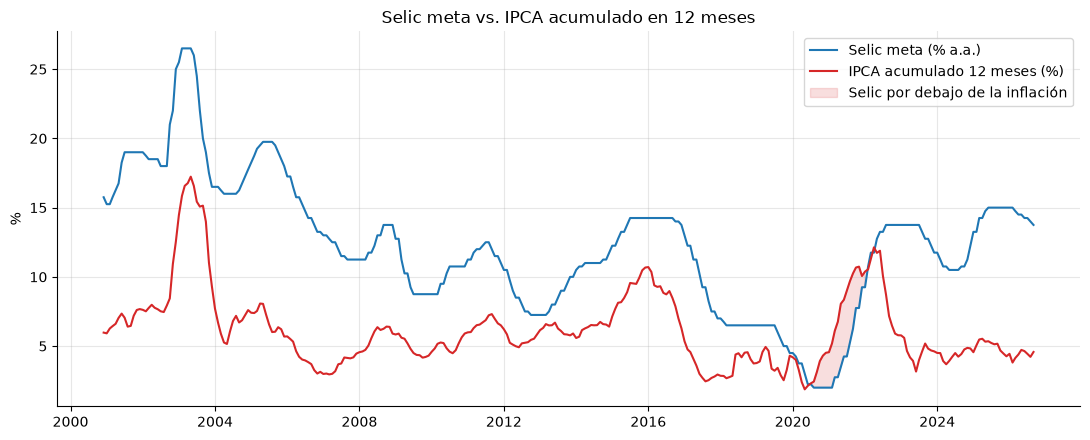

In [4]:
fig, ax = plt.subplots()
ax.plot(mensual.index, mensual["selic"], color=COLOR_SELIC, label="Selic meta (% a.a.)")
ax.plot(mensual.index, mensual["ipca_12m"], color=COLOR_IPCA, label="IPCA acumulado 12 meses (%)")
ax.fill_between(mensual.index, mensual["selic"], mensual["ipca_12m"],
                where=mensual["selic"] < mensual["ipca_12m"],
                color=COLOR_IPCA, alpha=0.15, label="Selic por debajo de la inflación")
ax.set_title("Selic meta vs. IPCA acumulado en 12 meses")
ax.set_ylabel("%")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "selic_vs_ipca.png", dpi=120)
plt.show()

### Tasa de interés real por año

Tasa real de cada año con la ecuación de Fisher, a partir de la Selic promedio del año
y el IPCA acumulado del año (consulta `ipca_anual` de `sql/consultas.sql`). Un valor
negativo significa que la tasa de interés no alcanzó a cubrir la inflación.

In [5]:
anual = ejecutar("ipca_anual")
anual.tail(10)

,anio,meses,ipca_acumulado_pct,selic_promedio,tasa_real_pct
17,2017,12,2.95,10.15,6.99
18,2018,12,3.75,6.58,2.73
19,2019,12,4.31,6.04,1.66
20,2020,12,4.52,2.89,-1.56
21,2021,12,10.06,4.54,-5.02
22,2022,12,5.78,12.55,6.40
23,2023,12,4.62,13.30,8.30
24,2024,12,4.83,10.94,5.83
25,2025,12,4.26,14.42,9.74
26,2026,9,3.95,14.45,10.10


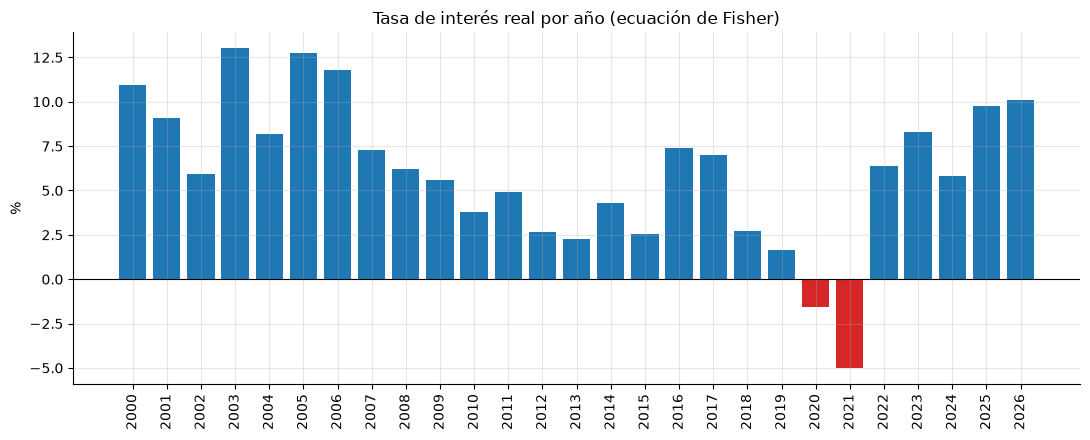

In [6]:
colores = [COLOR_IPCA if v < 0 else COLOR_SELIC for v in anual["tasa_real_pct"]]
fig, ax = plt.subplots()
ax.bar(anual["anio"], anual["tasa_real_pct"], color=colores)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Tasa de interés real por año (ecuación de Fisher)")
ax.set_ylabel("%")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "tasa_real_anual.png", dpi=120)
plt.show()

## 3. Evolución del dólar

In [7]:
dolar = (series[series["codigo"] == 1]
         .set_index("fecha")["valor"]
         .sort_index())
extremos = ejecutar("maximos_minimos")
extremos_dolar = extremos[extremos["codigo"] == 1]
extremos_dolar

,codigo,nombre,tipo,fecha,valor
0,1,Dólar venta (BRL/USD),máximo,2025-01-02,6.2086
1,1,Dólar venta (BRL/USD),mínimo,2011-07-26,1.5345


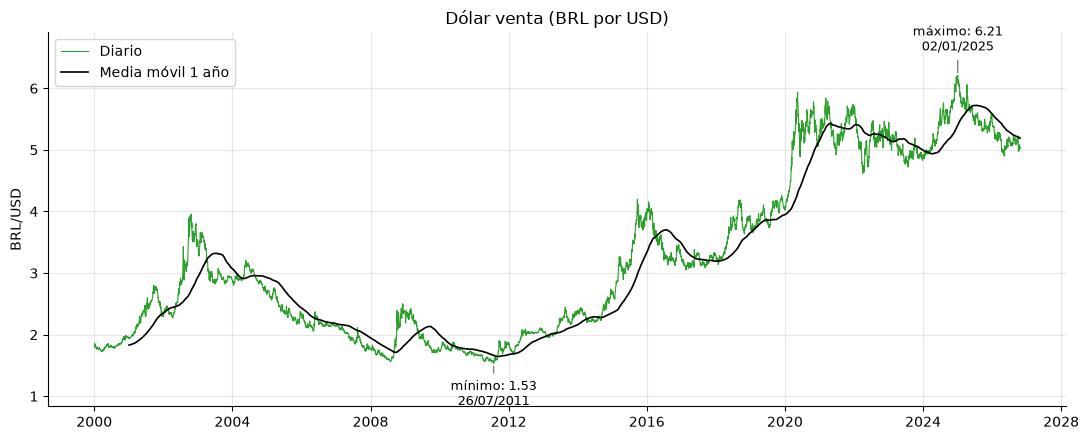

In [8]:
fig, ax = plt.subplots()
ax.plot(dolar.index, dolar, color=COLOR_DOLAR, linewidth=0.8, label="Diario")
ax.plot(dolar.rolling(252).mean(), color="black", linewidth=1.2, label="Media móvil 1 año")
for _, fila in extremos_dolar.iterrows():
    fecha = pd.to_datetime(fila["fecha"])
    ax.annotate(f"{fila['tipo']}: {fila['valor']:.2f}\n{fecha:%d/%m/%Y}",
                xy=(fecha, fila["valor"]), xytext=(0, 18 if fila["tipo"] == "máximo" else -30),
                textcoords="offset points", ha="center", fontsize=9,
                arrowprops={"arrowstyle": "-", "color": "gray"})
# Margen arriba y abajo para que las etiquetas de máximo y mínimo no se corten
ax.set_ylim(dolar.min() - 0.7, dolar.max() + 0.7)
ax.set_title("Dólar venta (BRL por USD)")
ax.set_ylabel("BRL/USD")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "dolar.png", dpi=120)
plt.show()

### Variación mensual del dólar

Variación % del cierre de cada mes frente al mes anterior (consulta `variacion_mensual`).

In [9]:
variacion = ejecutar("variacion_mensual")
var_dolar = variacion[variacion["codigo"] == 1].dropna(subset=["variacion_pct"])

print("Meses con mayor suba del dólar:")
print(var_dolar.nlargest(5, "variacion_pct")[["mes", "valor", "variacion_pct"]].to_string(index=False))
print("\nMeses con mayor baja del dólar:")
print(var_dolar.nsmallest(5, "variacion_pct")[["mes", "valor", "variacion_pct"]].to_string(index=False))

Meses con mayor suba del dólar:
    mes  valor  variacion_pct
2002-09 3.8949          28.87
2002-07 3.4285          20.54
2008-09 1.9143          17.13
2011-09 1.8544          16.83
2020-03 5.1987          15.56

Meses con mayor baja del dólar:
    mes  valor  variacion_pct
2003-04 2.8898         -13.82
2002-08 3.0223         -11.85
2016-06 3.2098         -10.72
2016-03 3.5589         -10.57
2009-05 1.9730          -9.42


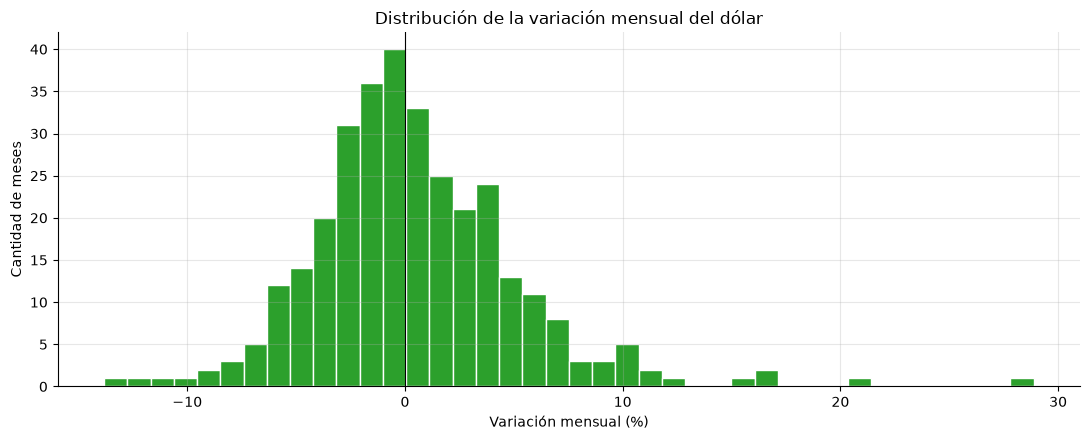

In [10]:
fig, ax = plt.subplots()
ax.hist(var_dolar["variacion_pct"], bins=40, color=COLOR_DOLAR, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Distribución de la variación mensual del dólar")
ax.set_xlabel("Variación mensual (%)")
ax.set_ylabel("Cantidad de meses")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "dolar_variacion_mensual.png", dpi=120)
plt.show()

## 4. Resumen en números

In [11]:
ultimo = mensual.iloc[-1]
resumen = pd.Series({
    "Último mes con IPCA": f"{mensual.index[-1]:%m/%Y}",
    "Selic meta (%)": ultimo["selic"],
    "IPCA 12 meses (%)": round(ultimo["ipca_12m"], 2),
    "Tasa real, Fisher (%)": round(ultimo["tasa_real"], 2),
    "Dólar último dato": f"{dolar.iloc[-1]:.4f} ({dolar.index[-1]:%d/%m/%Y})",
    "Años con tasa real negativa": ", ".join(anual.loc[anual["tasa_real_pct"] < 0, "anio"]),
})
resumen.to_frame("valor")

,valor
Último mes con IPCA,09/2026
Selic meta (%),13.75
IPCA 12 meses (%),4.58
"Tasa real, Fisher (%)",8.77
Dólar último dato,5.0377 (23/10/2026)
Años con tasa real negativa,"2020, 2021"


## 5. Observaciones

*Con datos cargados al 26/10/2026.*

- **Tasa real casi siempre positiva:** desde 2000 la Selic promedio superó al IPCA de cada
  año, salvo en **2020 y 2021**. En 2020 la Selic bajó a su mínimo histórico (2 %) y en 2021
  la inflación subió por encima del 10 %, sin que la Selic alcanzara a acompañarla.
- **Picos de la Selic:** el máximo fue 26,5 % en febrero de 2003, en respuesta a la inflación
  de fines de 2002. Hoy la Selic meta está en 13,75 %, con un IPCA de 12 meses cerca del 4,6 %:
  una de las tasas reales más altas de la serie.
- **El dólar casi se triplicó desde 2000** (de 1,83 a 5,04 BRL), con altibajos: su mínimo fue
  1,53 BRL (julio de 2011) y su máximo 6,21 BRL (enero de 2025).
- **Saltos bruscos en momentos de crisis:** las mayores subas mensuales del dólar ocurrieron en
  2002 (+28,9 % en septiembre), en la crisis financiera de 2008 y al inicio de la pandemia
  (+15,6 % en marzo de 2020).